# FarmTech Vision — O começo da rede neural
**Gabriel Marcolino Ramos — RM565717**  
**E-mail acadêmico:** rm565717@fiap.com.br  
FIAP · Inteligência Artificial · Fase 6 · Grupo 74 · integrante único

## 1. Problema e objetivo
A FarmTech Solutions deseja demonstrar visão computacional para um cliente fictício. O protótipo localiza **gatos e carros** em fotografias e compara detecção de objetos com classificação da imagem. As classes contrastam um animal doméstico e um veículo, compatíveis com uma demonstração inicial de monitoramento de ambientes. O experimento não identifica pessoas nem autoriza acesso.

As entregas obrigatórias incluem: base 40+40, divisão 32/4/4 por classe, YOLO customizado com 30 e 60 épocas, YOLO padrão sem ajuste local e CNN com inicialização aleatória. O relatório apresenta métricas reais de execução, tempo, erros e limitações. O programa opcional “Ir Além” não integra este escopo.

## 2. Como executar
No Colab, selecionar uma GPU e executar em ordem. A primeira célula obtém o repositório e instala as dependências; a segunda conecta o Drive. Em Jupyter local, abrir o notebook com o ambiente indicado no README. O código completo está nos módulos `src/` e é chamado nas células abaixo.

Por padrão, **REUTILIZAR_TREINOS=True** conserva os experimentos reais registrados no repositório e permite inspecionar e repetir a avaliação sem novo treino. Para repetir as 30/60 épocas e a CNN, definir **False**. Os tempos preservados pertencem aos treinos originais da GPU identificada no ambiente. Uma nova execução pode produzir tempos e resultados diferentes. Não executar nem salvar novos commits depois de formalizar a entrega acadêmica.

In [1]:
from pathlib import Path
import os, sys, subprocess, importlib.util

# O caminho local é descoberto; no Colab o projeto é clonado em /content.
IN_COLAB = importlib.util.find_spec("google.colab") is not None
REPO_URL = "https://github.com/FIAP-PROJECTS-GABRIEL-MARCOLINO-RAMOS/farmtech-fase6-gabriel-marcolino-ramos.git"
if IN_COLAB:
    ROOT = Path("/content/farmtech-fase6")
    if not ROOT.exists():
        subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/dataset.py").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
# Desativa integrações de logging em serviços externos.
os.environ.update({"WANDB_MODE": "disabled", "COMET_MODE": "DISABLED", "MPLBACKEND": "Agg",
                   "YOLOv5_AUTOINSTALL": "false", "OMP_NUM_THREADS": "2"})
subprocess.run([sys.executable, "scripts/bootstrap.py"], check=True)
REUTILIZAR_TREINOS = True
print("Ambiente:", "Colab" if IN_COLAB else "Jupyter local", "| Projeto:", ROOT.name)

YOLOv5 v7.0 verificado: 915bbf294bb74c859f0b41f1c23bc395014ea679; checkpoint: yolov5n.pt
Ambiente: Jupyter local | Projeto: farmtech-fase6


### 2.1 Google Drive e persistência
O dataset mantém `images/train`, `images/val`, `images/test` e os rótulos em `labels/`. No Colab, os arquivos são copiados para o Drive, mas o treinamento lê o disco local para evitar a latência de arquivos remotos. Ao final, os modelos e resultados também são persistidos no Drive. A montagem exige autenticação do titular. A execução documentada neste notebook ocorreu **localmente**; o fluxo do Drive é condicionado ao Colab.

In [2]:
import shutil
DRIVE_PROJECT = None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_PROJECT = Path("/content/drive/MyDrive/FarmTech_Fase6_GabrielMarcolinoRamos_rm565717")
    DRIVE_PROJECT.mkdir(parents=True, exist_ok=True)
    for name in ("images", "labels", "annotations_voc"):
        shutil.copytree(ROOT / "data" / name, DRIVE_PROJECT / "dataset" / name, dirs_exist_ok=True)
    shutil.copy2(ROOT / "data/manifest.csv", DRIVE_PROJECT / "dataset/manifest.csv")
    print("Dataset persistido em:", DRIVE_PROJECT / "dataset")
else:
    print("Execução local: base e rótulos preservados em data/. A montagem do Drive só ocorre no Colab.")

Execução local: base e rótulos preservados em data/. A montagem do Drive só ocorre no Colab.


In [3]:
import json, random, inspect
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown, Image as DisplayImage
from src.dataset import audit, SEED
from src.experiments import train_yolo, train_cnn, SmallCNN, seed_all
seed_all()
print("Semente:", SEED, "| PyTorch:", torch.__version__)
print("Dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
display(pd.Series(json.loads((ROOT / "results/environment.json").read_text()), name="Execução original"))

Semente: 565717 | PyTorch: 2.5.1+cu124
Dispositivo: NVIDIA GeForce RTX 3050 6GB Laptop GPU


python                                                      3.12.3
torch                                                  2.5.1+cu124
platform             Linux-6.17.0-35-generic-x86_64-with-glibc2.39
cuda_runtime                                                  12.4
gpu                         NVIDIA GeForce RTX 3050 6GB Laptop GPU
yolov5_commit             915bbf294bb74c859f0b41f1c23bc395014ea679
precision                                      FP32 para avaliação
latency_scope    leitura local + pré-processamento + rede + NMS...
Name: Execução original, dtype: object

## 3. Base, seleção e rastreabilidade
Foram selecionadas 80 imagens reais do **COCO 2017 validation**. A semente 565717 fixa a seleção e a divisão. Cada imagem contém apenas uma das duas classes de interesse, embora possa incluir vários objetos dessa classe e objetos de outras categorias. A maior caixa de interesse ocupa pelo menos 10% da imagem; regiões `crowd` foram excluídas. Esses filtros tornam a tarefa mais controlada e reduzem sua abrangência.

As imagens originais e suas licenças CC BY, BY-SA, BY-NC ou BY-NC-SA constam em `manifest.csv`, com URL COCO, página Flickr e SHA-256. O uso desta seleção é acadêmico e não comercial. As caixas de referência provêm de anotações humanas do COCO. Os formatos YOLO e Pascal VOC são conversões dessas anotações; não são rótulos previstos pelo modelo.

**Make Sense AI:** as 64 imagens e caixas Pascal VOC foram importadas na ferramenta em 15/10/2026. A conferência visual por amostragem preservou as anotações humanas COCO; a exportação YOLO original está em `data/makesense/`, com comparação numérica de todos os arquivos. A diferença para os rótulos fracionários de treino decorre do arredondamento VOC (até 0,501 pixel). Ver `docs/rotulacao.md`.

In [4]:
# Auditoria: 80 arquivos válidos, contagens, hashes e caixas normalizadas.
audit_result = audit()
display(pd.Series(audit_result, name="Auditoria da base"))
manifest = pd.read_csv(ROOT / "data/manifest.csv")
display(pd.crosstab(manifest.class_name, manifest.split)[["train", "val", "test"]])
display(manifest[["image_id", "class_name", "split", "boxes", "license"]].head(10))

images                                                                        80
boxes                                                                        155
counts                         {'gato/test': 4, 'carro/test': 4, 'gato/train'...
seed                                                                      565717
id_overlap                                                                     0
sha256_overlap                                                                 0
dhash_threshold                                                                4
similar_pairs                  [{'image_a': '163155', 'image_b': '255965', 'd...
similar_pairs_across_splits                                                    0
annotation_source              COCO 2017; conversão automática para YOLO e Pa...
makesense_review               {'date': '2026-10-15', 'tool': 'https://www.ma...
Name: Auditoria da base, dtype: object

split,train,val,test
class_name,,,
carro,32,4,4
gato,32,4,4


,image_id,class_name,split,boxes,license
0,177015,gato,test,1,Attribution License
1,187236,gato,test,2,Attribution-NonCommercial-ShareAlike License
2,284623,gato,test,1,Attribution License
3,443303,gato,test,1,Attribution-NonCommercial License
4,97679,carro,test,2,Attribution License
5,274411,carro,test,2,Attribution-NonCommercial License
6,527220,carro,test,1,Attribution-NonCommercial-ShareAlike License
7,560474,carro,test,1,Attribution-NonCommercial-ShareAlike License
8,4795,gato,train,1,Attribution-NonCommercial-ShareAlike License
9,15497,gato,train,1,Attribution-NonCommercial-ShareAlike License


Não há IDs ou SHA-256 repetidos entre as partições. A triagem por dHash (distância até 4) encontrou um par de cenas muito semelhantes, **163155 e 255965**, ambas de gatos e ambas no treino. A revisão visual confirmou o mesmo animal e cenário em duas fotografias; o par não cruza treino e avaliação. O dHash é uma heurística e não garante a ausência de todas as cenas relacionadas. As duas fotografias reduzem a diversidade efetiva do treino, apesar de serem arquivos distintos.

In [5]:
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from matplotlib.patches import Rectangle

# Mostra exemplos do treino com todas as caixas de referência da classe.
examples = manifest[manifest.split == "train"].groupby("class_name", sort=True).head(3)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), constrained_layout=True)
for ax, row in zip(axes.flat, examples.itertuples()):
    im = PILImage.open(ROOT / row.file)
    ax.imshow(im)
    labels = np.loadtxt(ROOT / "data/labels/train" / (Path(row.file).stem + ".txt"), ndmin=2)
    for cls, cx, cy, w, h in labels:
        ax.add_patch(Rectangle(((cx-w/2)*im.width, (cy-h/2)*im.height), w*im.width, h*im.height,
                               fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{row.class_name} · COCO {row.image_id}")
    ax.axis("off")
plt.show()

/tmp/ipykernel_1031919/2943209938.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 4. Desenho dos experimentos e métricas
As partições são fixas: 64 imagens de treino, 8 de validação e 8 de teste. A validação escolhe checkpoints e a configuração customizada; o teste é consultado apenas na avaliação final. **Os dois YOLOs partem independentemente do mesmo `yolov5n.pt` pré-treinado**, não há continuação do treino de 30 para 60 épocas. Mantêm-se semente, 416 pixels, batch 8, SGD e hiperparâmetros da versão v7.0. A mudança principal é o número de épocas; o agendamento de learning rate também depende dessa duração.

Para detecção: **mAP50** e **mAP50–95** avaliam classe e localização. A AP considera previsões a partir de confiança 0,001 e IoUs de 0,50 a 0,95. A precisão e a revocação reportadas usam **confiança fixa 0,25**, IoU 0,50 e NMS 0,45. Há correspondência de no máximo uma detecção por caixa verdadeira. Não se usa o termo “acurácia” como sinônimo de mAP.

Para comparar também a CNN, define-se uma tarefa comum mais simples: classificar a imagem como gato ou carro. No YOLO vale a detecção de maior confiança entre as duas classes; abaixo de 0,25 há **abstenção**, contada como erro. A CNN sempre escolhe uma classe. Reportam-se acurácia por imagem e F1 macro; essas métricas não avaliam localização e não substituem mAP.

O YOLO padrão já aprendeu as classes no COCO. Os pesos foram treinados com COCO train2017; este subconjunto vem de val2017, usado também no ecossistema para desenvolvimento/seleção de modelos. Portanto, esta comparação é uma demonstração exploratória, não um benchmark inteiramente independente do pré-treinamento. A CNN parte de pesos aleatórios e possui uma desvantagem informacional clara com somente 64 imagens.

## 5. Entrega 1 — customização YOLOv5
YOLOv5n é a variante pequena, escolhida para repetir os experimentos com recursos locais limitados. O script oficial gera `results.csv`, curvas de loss, métricas e `best.pt`. O melhor checkpoint interno usa a fitness oficial: 10% mAP50 + 90% mAP50–95 da validação.

O notebook conserva os registros originais e os melhores pesos em `models/`. Os logs dos comandos reais estão em `results/yolov5n_30ep.log` e `results/yolov5n_60ep.log`. O script completo de treinamento é visível a seguir.

In [6]:
# Implementação usada nos dois experimentos (inclui o comando oficial de treinamento).
print(inspect.getsource(train_yolo))

def train_yolo(epochs: int, reuse: bool = True) -> dict:
    """Sempre inicia do mesmo checkpoint COCO; reutiliza só execução concluída."""
    audit()
    name = f"yolov5n_{epochs}ep"
    record = ROOT / f"results/{name}_train.json"
    if record.exists() and reuse:
        print(f"Treino concluído preservado: {name}")
        return json.loads(record.read_text())
    command = [sys.executable, "train.py", "--data", str(ROOT / "data/dataset-local.yaml"),
               "--weights", str(ROOT / "models/yolov5n.pt"), "--img", "416", "--batch-size", "8",
               "--epochs", str(epochs), "--seed", str(SEED), "--workers", "0", "--patience", "0",
               "--device", "0" if torch.cuda.is_available() else "cpu",
               "--project", str(ROOT / "results/runs"), "--name", name, "--exist-ok"]
    env = {**os.environ, "WANDB_MODE": "disabled", "COMET_MODE": "DISABLED", "MPLBACKEND": "Agg",
           "OMP_NUM_THREADS": "2", "OPENBLAS_NUM_THREADS": "2", "YOLOv5_AUTOINSTALL": "f

In [7]:
# Primeiro experimento: 30 épocas a partir dos pesos pré-treinados originais.
run_30 = train_yolo(30, reuse=REUTILIZAR_TREINOS)
display(pd.Series(run_30, name="YOLOv5n · 30 épocas"))

Treino concluído preservado: yolov5n_30ep


model                                         yolov5n_30ep
epochs                                                  30
training_seconds                                 69.189761
best_epoch                                              29
best_fitness                                      0.296747
seed                                                565717
imgsz                                                  416
batch                                                    8
initial_weights             yolov5n.pt — COCO pré-treinado
selection_split                                        val
device              NVIDIA GeForce RTX 3050 6GB Laptop GPU
Name: YOLOv5n · 30 épocas, dtype: object

In [8]:
# Segundo experimento: mesmo ponto inicial, com 60 épocas.
run_60 = train_yolo(60, reuse=REUTILIZAR_TREINOS)
display(pd.Series(run_60, name="YOLOv5n · 60 épocas"))

Treino concluído preservado: yolov5n_60ep


model                                         yolov5n_60ep
epochs                                                  60
training_seconds                                116.613928
best_epoch                                              54
best_fitness                                       0.35498
seed                                                565717
imgsz                                                  416
batch                                                    8
initial_weights             yolov5n.pt — COCO pré-treinado
selection_split                                        val
device              NVIDIA GeForce RTX 3050 6GB Laptop GPU
Name: YOLOv5n · 60 épocas, dtype: object

,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
30 épocas: última,29.0,0.062598,0.027744,0.004560,0.53176,0.51165,0.46653,0.26969,0.066112,0.011230,0.004724,0.00076,0.00076,0.00076
60 épocas: última,59.0,0.054672,0.024874,0.001608,0.94312,0.47222,0.54363,0.31356,0.061545,0.010422,0.005134,0.00043,0.00043,0.00043


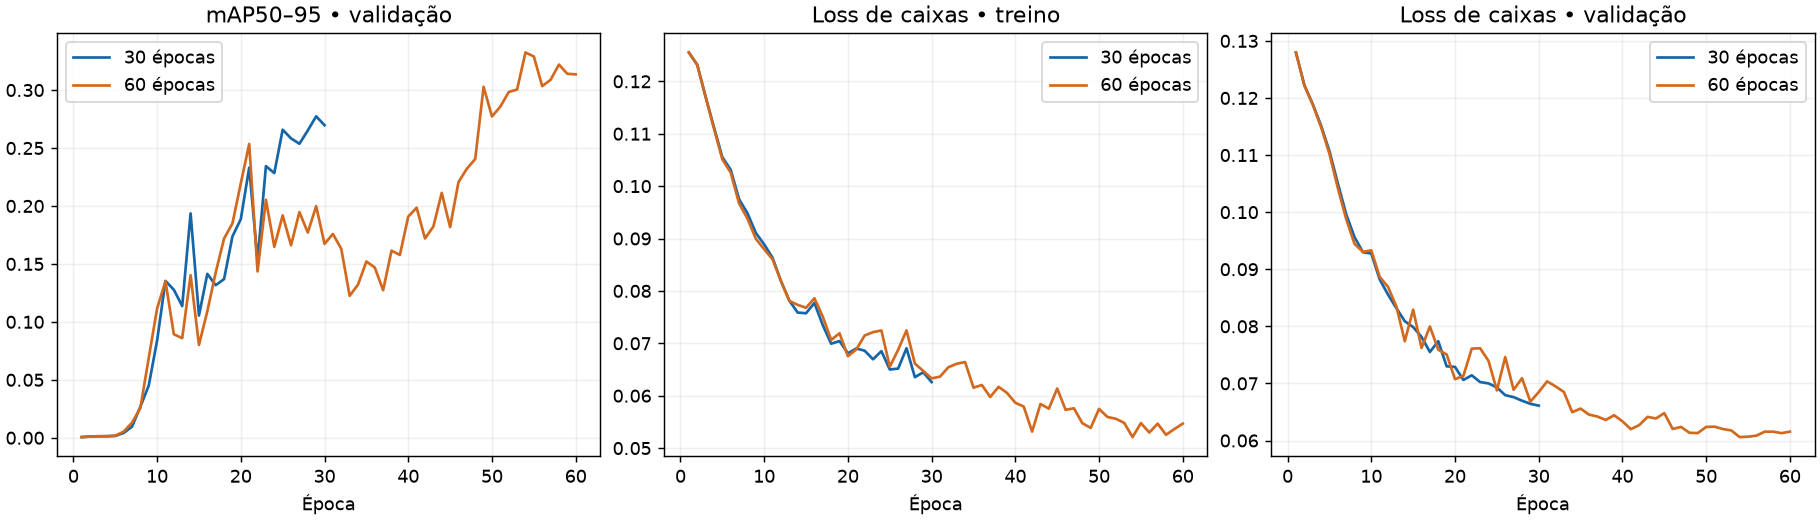

In [9]:
history30 = pd.read_csv(ROOT / "results/yolov5n_30ep_history.csv")
history60 = pd.read_csv(ROOT / "results/yolov5n_60ep_history.csv")
display(pd.DataFrame([history30.iloc[-1], history60.iloc[-1]], index=["30 épocas: última", "60 épocas: última"]))
display(DisplayImage(filename=str(ROOT / "results/yolo_learning_curves.png")))

Na execução original, o treino de 30 épocas levou aproximadamente **69,2 s** e escolheu a época **29**; o de 60 levou **116,6 s** e escolheu a época **54**. O melhor checkpoint pode anteceder a última época; usar sempre a última pode descartar uma validação melhor.

As curvas registram a redução das perdas ao longo do treino, mas as oito imagens de validação tornam a estimativa instável. A loss de treino não prova generalização. As métricas internas do script oficial usam seu carregamento retangular e configurações de avaliação; a comparação final abaixo padroniza entrada quadrada e NMS para todos os detectores. Por isso os números internos e os da comparação final podem diferir.

## 6. Entrega 2 — YOLO padrão e CNN do zero
O **YOLO padrão** é o checkpoint YOLOv5n COCO sem ajuste local: seus IDs 15 (cat) e 2 (car) são explicitamente remapeados para 0 (gato) e 1 (carro). Isso mantém a mesma família/escala do detector e isola o efeito da customização.

A **CNN do zero** tem três blocos Conv2d/ReLU/MaxPool, com 16, 32 e 64 canais, pooling adaptativo, camada densa de 64 unidades e dropout 0,3. A entrada é 128×128; treinamento com Adam, learning rate 0,001, weight decay 0,0001, batch 8 e 60 épocas. Há espelhamento e pequena variação de cor somente no treino. Nenhum peso ImageNet é usado. O checkpoint é escolhido pela menor entropia cruzada na validação.

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): AdaptiveAvgPool2d(output_size=(4, 4))
    (1): Flatten(start_dim=1, end_dim=-1)
    (2): Linear(in_features=1024, out_features=64, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.3, inplace=False)
    (5): Linear(in_features=64, out_features=2, bias=True)
  )
)
Parâmetros da CNN: 89314


model                              cnn_zero
epochs                                   60
training_seconds                  19.523088
best_epoch                                7
best_val_loss                      0.618316
seed                                 565717
parameters                            89314
class_to_idx        {'carro': 0, 'gato': 1}
device                               cuda:0
selection_split                         val
pretrained                            False
Name: CNN com inicialização aleatória, dtype: object

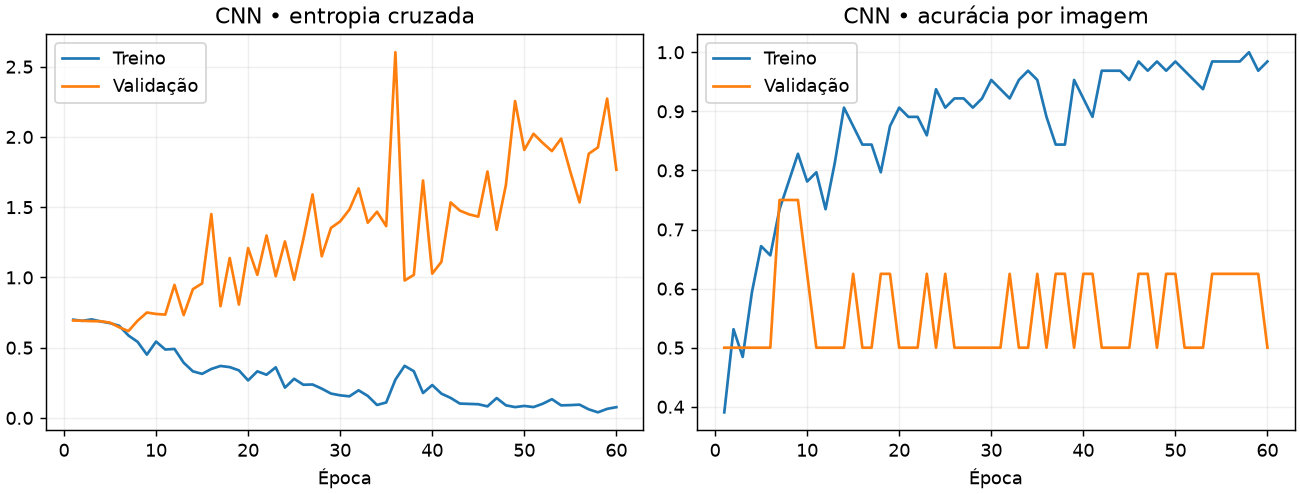

In [10]:
print(SmallCNN())
print("Parâmetros da CNN:", sum(p.numel() for p in SmallCNN().parameters()))
run_cnn = train_cnn(60, reuse=REUTILIZAR_TREINOS)
display(pd.Series(run_cnn, name="CNN com inicialização aleatória"))
display(DisplayImage(filename=str(ROOT / "results/cnn_learning_curves.png")))

Na execução original, a CNN alcançou **98,4% no treino na época 60**, mas o checkpoint de menor loss de validação ocorreu na **época 7**. A loss de validação aumentou depois, sinal de sobreajuste. O treino levou aproximadamente **19,5 s**. A melhor época é determinada sem usar o conjunto de teste. Os índices alfabéticos do ImageFolder (`carro=0`, `gato=1`) são convertidos para os IDs do projeto na avaliação; ignorar essa conversão inverteria os resultados.

## 7. Validação padronizada e teste final
Os detectores usam FP32, batch 1 e entrada 416×416 na avaliação. O código processa inicialmente a validação e registra a escolha em `model_selection.json`, antes do teste. A CNN usa 128×128 e não produz caixas, portanto não tem mAP.

O tempo de inferência inclui leitura local, pré-processamento e rede; no YOLO inclui também NMS. Exclui carga dos pesos, aquecimento e gravação das figuras. São cinco aquecimentos e cinco passagens por imagem, com sincronização CUDA. A mediana e o percentil 95 resumem 40 medidas por conjunto. Diferenças de resolução e tarefa impedem interpretar a latência como uma competição estrita de arquiteturas.

In [11]:
from src.evaluation import evaluate_all
# Reexecuta a avaliação sobre os checkpoints reais; não altera os pesos.
comparison = evaluate_all()
cols = ["model", "split", "map50", "map50_95", "precision_at025", "recall_at025",
        "image_accuracy", "macro_f1", "latency_ms_median", "training_seconds"]
display(comparison[cols].round(4))
selection = json.loads((ROOT / "results/model_selection.json").read_text())
display(pd.Series(selection, name="Seleção anterior ao teste"))

/home/acer-nitro/work/FIAP/farmtech-fase6/vendor/yolov5/models/experimental.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(attempt_download(w), map_l

YOLOv5n summary: 213 layers, 1867405 parameters, 0 gradients, 4.5 GFLOPs


{
  "model": "yolo_padrao",
  "split": "val",
  "task": "detection",
  "map50": 0.6804715119010336,
  "map50_95": 0.5350156659098027,
  "precision_at025": 1.0,
  "recall_at025": 0.5384615384615384,
  "tp": 7,
  "fp": 0,
  "fn": 6,
  "gt_boxes": 13,
  "per_class": {
    "0": {
      "tp": 2,
      "fp": 0,
      "gt": 4,
      "map50": 0.6950806451612903,
      "map50_95": 0.5453709677419354,
      "precision_at025": 1.0,
      "recall_at025": 0.5
    },
    "1": {
      "tp": 5,
      "fp": 0,
      "gt": 9,
      "map50": 0.6658623786407768,
      "map50_95": 0.52466036407767,
      "precision_at025": 1.0,
      "recall_at025": 0.5555555555555556
    }
  },
  "latency_ms_median": 6.2198419996093435,
  "latency_ms_p95": 7.767399699287125,
  "latency_samples": 40,
  "imgsz": 416,
  "confidence": 0.25,
  "ap_confidence_min": 0.001,
  "nms_iou": 0.45,
  "image_accuracy": 0.625,
  "correct_images": 5,
  "image_count": 8,
  "error_rate": 0.375,
  "macro_f1": 0.7619047619047619,
  "abstentio

/home/acer-nitro/work/FIAP/farmtech-fase6/vendor/yolov5/models/experimental.py:79: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(attempt_download(w), map_l

Model summary: 157 layers, 1761871 parameters, 0 gradients, 4.1 GFLOPs


...

Model summary: 157 layers, 1761871 parameters, 0 gradients, 4.1 GFLOPs


{
  "model": "yolov5n_60ep",
  "split": "test",
  "task": "detection",
  "map50": 0.5724729739121361,
  "map50_95": 0.365900375154227,
  "precision_at025": 0.6666666666666666,
  "recall_at025": 0.5454545454545454,
  "tp": 6,
  "fp": 3,
  "fn": 5,
  "gt_boxes": 11,
  "per_class": {
    "0": {
      "tp": 3,
      "fp": 2,
      "gt": 5,
      "map50": 0.6054252181393635,
      "map50_95": 0.3487197633385418,
      "precision_at025": 0.6,
      "recall_at025": 0.6
    },
    "1": {
      "tp": 3,
      "fp": 1,
      "gt": 6,
      "map50": 0.5395207296849087,
      "map50_95": 0.3830809869699123,
      "precision_at025": 0.75,
      "recall_at025": 0.5
    }
  },
  "latency_ms_median": 5.559157999869058,
  "latency_ms_p95": 7.0845598999312624,
  "latency_samples": 40,
  "imgsz": 416,
  "confidence": 0.25,
  "ap_confidence_min": 0.001,
  "nms_iou": 0.45,
  "image_accuracy": 0.75,
  "correct_images": 6,
  "image_count": 8,
  "error_rate": 0.25,
  "macro_f1": 0.8333333333333333,
  "abstent

{
  "model": "cnn_zero",
  "split": "test",
  "task": "classification",
  "imgsz": 128,
  "latency_ms_median": 3.9005574999464443,
  "latency_ms_p95": 6.204250449400206,
  "latency_samples": 40,
  "image_accuracy": 0.625,
  "correct_images": 5,
  "image_count": 8,
  "error_rate": 0.375,
  "macro_f1": 0.6190476190476191,
  "abstentions": 0,
  "accuracy_ci95_wilson": [
    0.30573785458380187,
    0.863158240538479
  ],
  "confusion_labels": [
    "gato",
    "carro",
    "sem_deteccao"
  ],
  "confusion_matrix": [
    [
      2,
      2,
      0
    ],
    [
      1,
      3,
      0
    ],
    [
      0,
      0,
      0
    ]
  ]
}


,model,split,map50,map50_95,precision_at025,recall_at025,image_accuracy,macro_f1,latency_ms_median,training_seconds
0,yolo_padrao,val,0.6805,0.5350,1.0000,0.5385,0.625,0.7619,6.2198,0.0000
1,yolov5n_30ep,val,0.5274,0.3157,0.6667,0.6154,0.875,0.9286,6.1692,69.1898
2,yolov5n_60ep,val,0.5987,0.3226,0.7000,0.5385,0.750,0.8571,5.8505,116.6139
3,cnn_zero,val,NaN,NaN,NaN,NaN,0.750,0.7333,3.8444,19.5231
4,yolo_padrao,test,0.7297,0.5232,1.0000,0.5455,0.500,0.6286,5.5371,0.0000
5,yolov5n_30ep,test,0.6149,0.3100,0.6364,0.6364,0.750,0.8333,5.6914,69.1898
6,yolov5n_60ep,test,0.5725,0.3659,0.6667,0.5455,0.750,0.8333,5.5592,116.6139
7,cnn_zero,test,NaN,NaN,NaN,NaN,0.625,0.6190,3.9006,19.5231


selected_model                                              yolov5n_60ep
criterion              maior mAP50-95 na validação; teste não partici...
validation_map50_95                                             0.322638
Name: Seleção anterior ao teste, dtype: object

,file,true_class,image_prediction
0,data/images/test/000000177015.jpg,0,0
1,data/images/test/000000187236.jpg,0,0
2,data/images/test/000000284623.jpg,0,0
3,data/images/test/000000443303.jpg,0,0
4,data/images/test/000000097679.jpg,1,1
5,data/images/test/000000274411.jpg,1,-1
6,data/images/test/000000527220.jpg,1,1
7,data/images/test/000000560474.jpg,1,-1


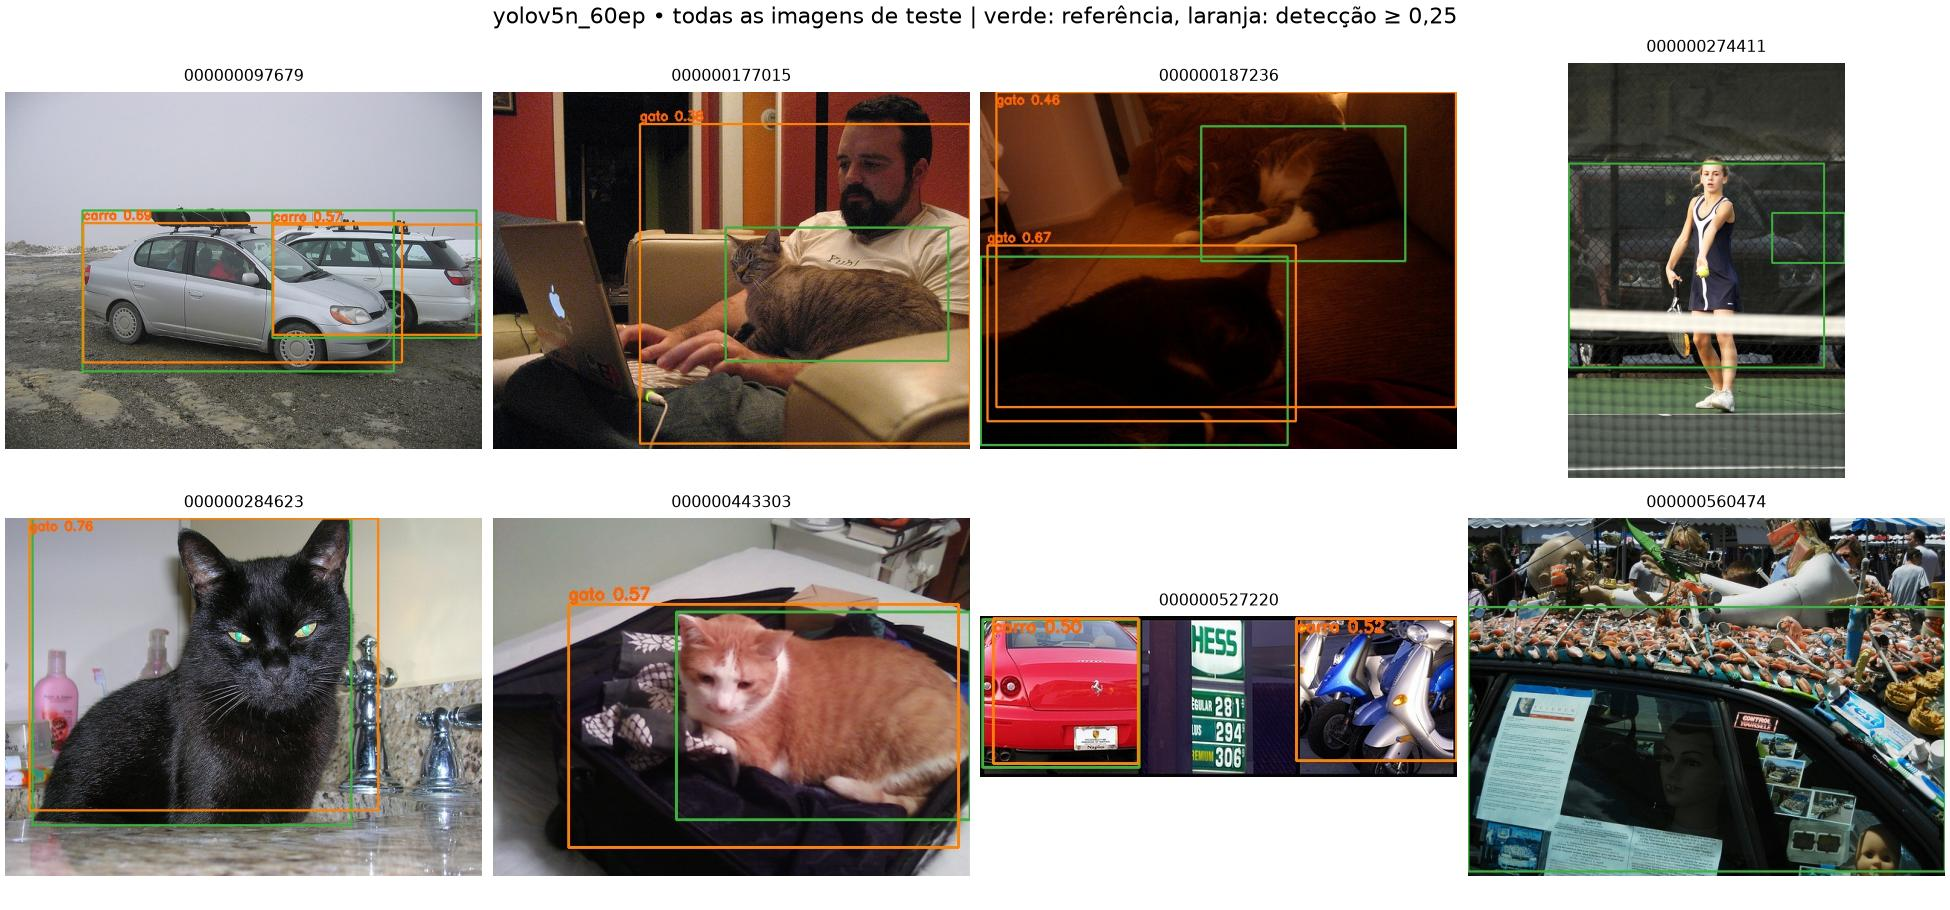

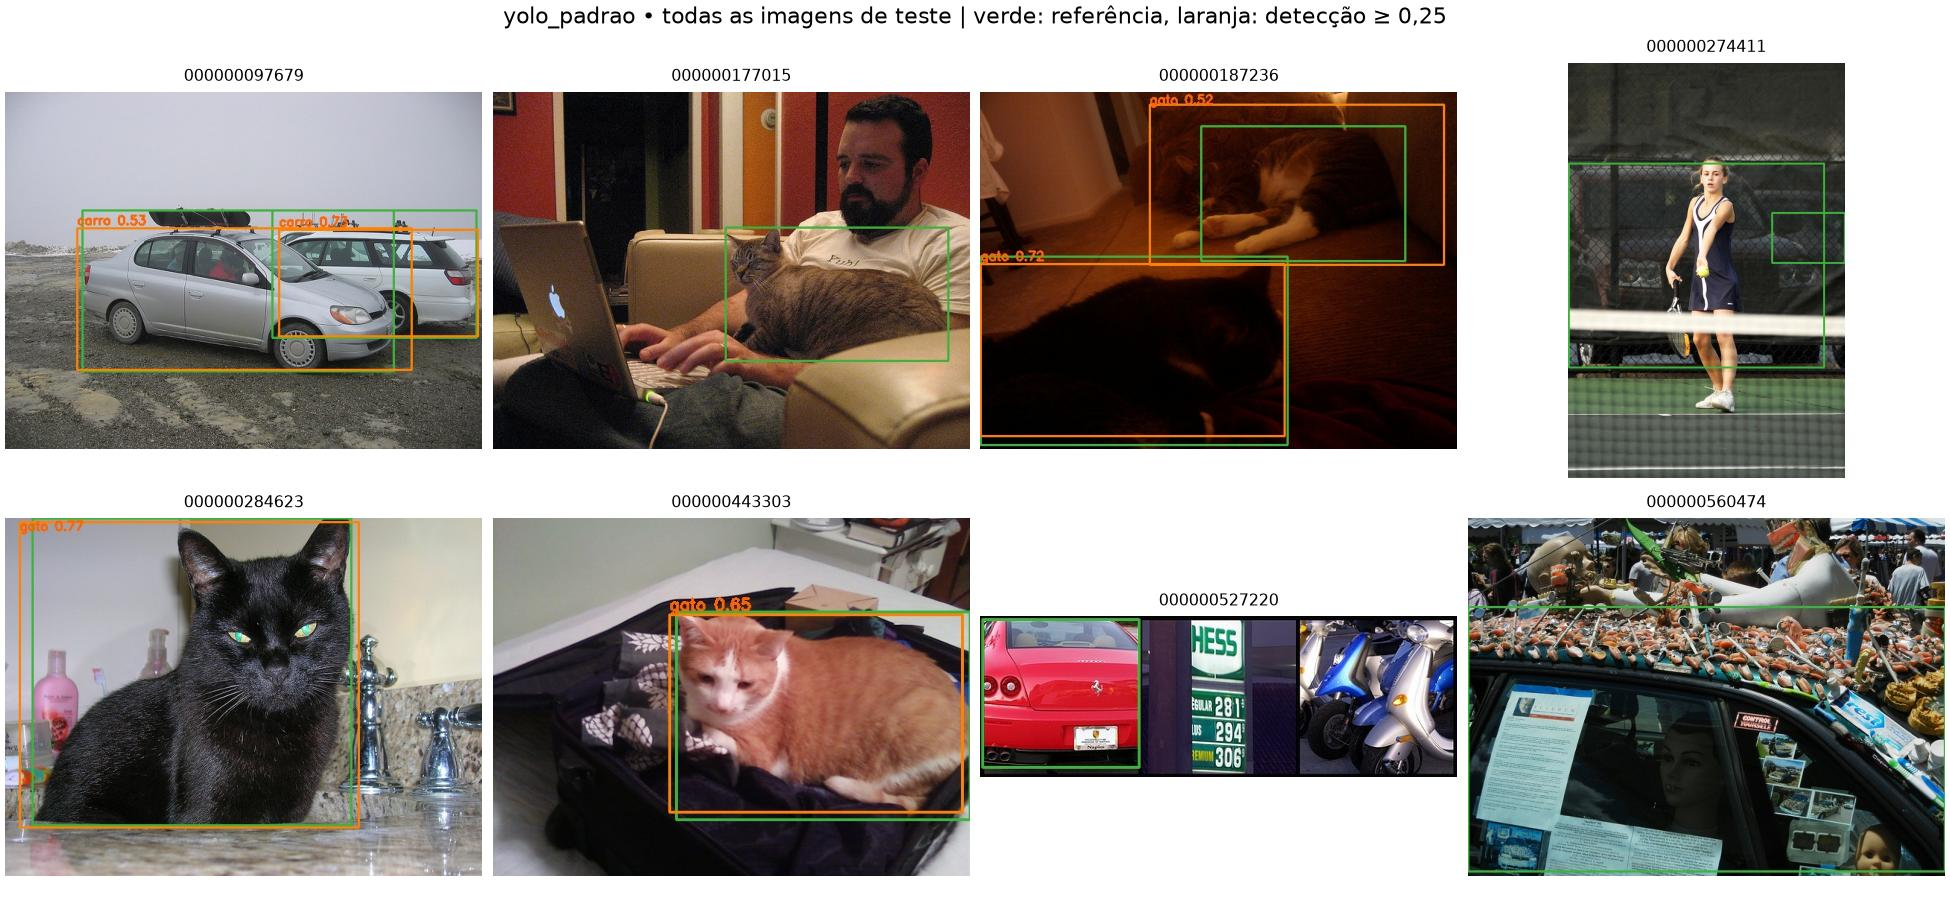

In [12]:
# Apresenta as oito previsões e os erros, incluindo abstenções.
chosen = selection["selected_model"]
test_details = pd.read_json(ROOT / f"results/{chosen}_test_predictions.json")
display(test_details[["file", "true_class", "image_prediction"]])
display(DisplayImage(filename=str(ROOT / f"results/{chosen}_test_montage.jpg")))
display(DisplayImage(filename=str(ROOT / "results/yolo_padrao_test_montage.jpg")))

In [13]:
# Intervalos refletem a incerteza da classificação com apenas oito imagens.
uncertainty = []
for name in ["yolo_padrao", "yolov5n_30ep", "yolov5n_60ep", "cnn_zero"]:
    result = json.loads((ROOT / f"results/{name}_test.json").read_text())
    uncertainty.append({"modelo": name, "acertos": result["correct_images"], "total": result["image_count"],
                        "acurácia": result["image_accuracy"], "IC95% Wilson": result["accuracy_ci95_wilson"],
                        "abstenções": result["abstentions"]})
display(pd.DataFrame(uncertainty))

,modelo,acertos,total,acurácia,IC95% Wilson,abstenções
0,yolo_padrao,4,8,0.500,"[0.21521252682444186, 0.7847874731755582]",4
1,yolov5n_30ep,6,8,0.750,"[0.40926987910258916, 0.9285223111419724]",2
2,yolov5n_60ep,6,8,0.750,"[0.40926987910258916, 0.9285223111419724]",2
3,cnn_zero,5,8,0.625,"[0.30573785458380187, 0.863158240538479]",0


## 8. Discussão crítica da execução original
**Efeito das épocas.** Na avaliação padronizada da validação, mAP50–95 passou de **0,316 (30 épocas)** para **0,323 (60 épocas)**. O ganho é pequeno para oito imagens. A configuração de 60 épocas foi escolhida por esse critério, sem consultar o teste. No teste, mAP50–95 foi **0,310 e 0,366**, respectivamente; entretanto, mAP50 caiu de **0,615 para 0,572**. Isso mostra que mais épocas não melhoraram todas as métricas. A customização de 60 épocas custou cerca de 1,7 vez o tempo da de 30.

**YOLO padrão.** Obteve mAP50–95 **0,523** no teste, superior aos modelos customizados nesta execução. Seu repertório pré-treinado é vantajoso para duas classes já conhecidas. Com confiança 0,25, porém, classificou corretamente somente **4 de 8 imagens**, com abstenções; mAP considera também previsões de baixa confiança e avalia caixas, enquanto a classificação exige superar um limiar fixo. Os resultados são compatíveis, não contraditórios. Não há evidência de que o ajuste com 64 imagens tenha melhorado globalmente o detector original.

**CNN.** O checkpoint da época 7 acertou **5 de 8 imagens de teste (62,5%)**, contra **6 de 8 (75%)** de cada YOLO customizado. A CNN é pequena e teve menor tempo de treino e menor latência típica, mas classifica a imagem inteira e não localiza objetos. Os intervalos de Wilson são amplos: 6/8 corresponde aproximadamente a **40,9%–92,9%**, e 5/8 a **30,6%–86,3%**. Não se pode afirmar uma superioridade estatística robusta com esta amostra.

**Integração.** O YOLO padrão oferece o caminho mais curto quando as classes já fazem parte de seu vocabulário. O YOLO customizado exige dataset com caixas, YAML, treino e validação, mas permite adaptar classes e cenários. A CNN exige menos anotação para classificação (um rótulo por imagem), embora sua arquitetura, regularização e diversidade de dados precisem de cuidado. Para monitoramento que exige localizar cada objeto, a CNN deste projeto é insuficiente.

**Recomendação ao cliente fictício.** O protótipo comprova execução local, comparação e inspeção de erros. Para estas classes, o checkpoint padrão é uma referência forte de localização. A configuração customizada selecionada pode ser demonstrada, mas os resultados não justificam implantação autônoma. O próximo experimento deve ampliar a base com cenas da aplicação real, negativos, coocorrência de classes, variações de câmera e divisão por origem/cena, repetindo sementes e avaliando em teste externo.

## 9. Limitações e conclusão
O conjunto tem só 40 imagens por classe e somente quatro por classe no teste. Os filtros privilegiam objetos relativamente grandes, e há duas fotos relacionadas no treino. Não foram testados vídeos, câmeras em tempo real, mudança de iluminação controlada, negativos nem falhas de aquisição. As licenças das imagens restringem reutilização; o cenário demonstrativo não equivale à operação real de uma fazenda.

O YOLO utiliza pré-treinamento COCO, enquanto a CNN é aleatória; essa diferença faz parte da análise, mas limita comparações causais entre arquiteturas. Há uma única semente e uma única divisão. A triagem de semelhança é heurística. As latências pertencem ao computador e às condições de execução descritos, sem garantia de desempenho em outra máquina.

A execução demonstrou o pipeline completo de dados, treinamento, validação, teste e comparação. A cópia das 80 imagens (64/8/8), do manifesto e do ZIP de rótulos no Drive foi verificada em 15/10/2026 (`docs/drive.json`). A revisão/exportação no MakeSense está documentada em `data/makesense/`. O [vídeo narrado por Gabriel](https://youtu.be/fcv1dElMhMU) foi publicado como não listado, com duração de 4min58s. O formulário de envio abriu pelo link superior do portal apesar do aviso de prazo encerrado. A confirmação da entrega deve ser verificada no portal; não realizar commits após o envio. Não há envio acadêmico confirmado apenas pela existência deste notebook.

In [14]:
if DRIVE_PROJECT is not None:
    # Persistência após a avaliação; a execução local não acessa o Drive.
    shutil.copytree(ROOT / "models", DRIVE_PROJECT / "models", dirs_exist_ok=True)
    shutil.copytree(ROOT / "results", DRIVE_PROJECT / "results", dirs_exist_ok=True,
                    ignore=shutil.ignore_patterns("runs"))
    print("Modelos e resultados salvos no Drive.")
else:
    print("Modelos e resultados preservados localmente em models/ e results/.")

Modelos e resultados preservados localmente em models/ e results/.


## 10. Referências
- [COCO — Common Objects in Context](https://cocodataset.org/) e [termos das imagens e anotações](https://cocodataset.org/#termsofuse). Fontes e licenças individuais no manifesto.
- [Lin et al., Microsoft COCO: Common Objects in Context](https://arxiv.org/abs/1405.0312), 2014.
- [Ultralytics YOLOv5 v7.0](https://github.com/ultralytics/yolov5/tree/v7.0), commit 915bbf294bb74c859f0b41f1c23bc395014ea679.
- [Ultralytics — Train Custom Data](https://docs.ultralytics.com/yolov5/tutorials/train-custom-data/).
- [PyTorch — treinamento de classificadores](https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html).
- [Make Sense AI](https://www.makesense.ai/) e [código-fonte](https://github.com/SkalskiP/make-sense).